# Convolutional Neural Networks (CNN) — Clasificación de Imágenes Deportivas (`sportimages`)
**Actividad:** Ejecución de 5 corridas experimentales variando hiperparámetros y arquitectura de la red neuronal convolucional (épocas, neuronas/filtros, capas, tamaño de lote, tasa de aprendizaje y optimizador), almacenando todos los resultados en la carpeta `resultados/`.

In [1]:
import cv2

img = cv2.imread('sportimages/sportimages/basket/basket2_0001.jpg')
print(img.shape[0], img.shape[1], img.shape[2], len(img.shape))

21 28 3 3


# 1. Importar Librerías

In [2]:
import os
import re
import time
import csv
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [3]:
import keras
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Input, BatchNormalization, SeparableConv2D, MaxPooling2D,
    Activation, Flatten, Dropout, Dense, Conv2D, LeakyReLU
)

os.makedirs('resultados', exist_ok=True)
print('TensorFlow:', tf.__version__, '| Keras:', keras.__version__)

TensorFlow: 2.21.0 | Keras: 3.15.1


# 2. Cargar Set de Imágenes (`sportimages`)
Se cargan las imágenes una sola vez en memoria para utilizar exactamente la misma partición de datos en las 5 corridas.

In [4]:
dirname = os.path.join(os.getcwd(), 'sportimages', 'sportimages')
imgpath = dirname + os.sep

images = []
directories = []
dircount = []
prevRoot = ''
cant = 0

print('leyendo imagenes de ', imgpath)

for root, dirnames, filenames in os.walk(imgpath):
    dirnames.sort()
    filenames.sort()
    for filename in filenames:
        if re.search(r'\.(jpg|jpeg|png|bmp|tiff)$', filename, re.IGNORECASE):
            cant = cant + 1
            filepath = os.path.join(root, filename)
            image = plt.imread(filepath)
            if len(image.shape) == 3:
                images.append(image)
            if prevRoot != root:
                print(root, cant)
                prevRoot = root
                directories.append(root)
                dircount.append(cant)
                cant = 0
dircount.append(cant)

dircount = dircount[1:]
dircount[0] = dircount[0] + 1
print('Directorios leidos:', len(directories))
print('Imagenes en cada directorio', dircount)
print('suma Total de imagenes en subdirs:', sum(dircount))

leyendo imagenes de  sportimages/sportimages/
sportimages/sportimages/americano 1
sportimages/sportimages/basket 9348
sportimages/sportimages/beisball 8823
sportimages/sportimages/boxeo 7752
sportimages/sportimages/ciclismo 7125
sportimages/sportimages/f1 7533
sportimages/sportimages/futbol 5053
sportimages/sportimages/golf 7617
sportimages/sportimages/natacion 9768
sportimages/sportimages/tenis 5172
Directorios leidos: 10
Imagenes en cada directorio [9349, 8823, 7752, 7125, 7533, 5053, 7617, 9768, 5172, 8936]
suma Total de imagenes en subdirs: 77128


# 3. Creación de Etiquetas y Clases

In [5]:
labels = []
indice = 0
for cantidad in dircount:
    for i in range(cantidad):
        labels.append(indice)
    indice = indice + 1
print('Cantidad etiquetas creadas: ', len(labels))

Cantidad etiquetas creadas:  77128


In [6]:
deportes = []
indice = 0
for directorio in directories:
    name = directorio.split(os.sep)
    print(indice, name[len(name)-1])
    deportes.append(name[len(name)-1])
    indice = indice + 1

0 americano
1 basket
2 beisball
3 boxeo
4 ciclismo
5 f1
6 futbol
7 golf
8 natacion
9 tenis


In [7]:
y = np.array(labels)
X = np.array(images, dtype=np.uint8) # convierto de lista a numpy

classes = np.unique(y)
nClasses = len(classes)
print('Total number of outputs : ', nClasses)
print('Output classes : ', classes)

Total number of outputs :  10
Output classes :  [0 1 2 3 4 5 6 7 8 9]


# 4. Sets de Entrenamiento, Validación y Test + Preprocesamiento

In [8]:
train_X, test_X, train_Y, test_Y = train_test_split(X, y, test_size=0.2, random_state=13)
print('Training data shape : ', train_X.shape, train_Y.shape)
print('Testing data shape : ', test_X.shape, test_Y.shape)

Training data shape :  (61702, 21, 28, 3) (61702,)
Testing data shape :  (15426, 21, 28, 3) (15426,)


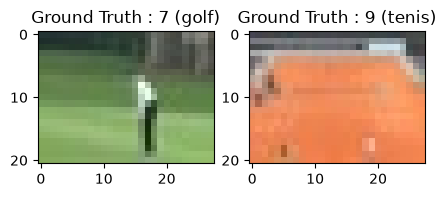

In [9]:
plt.figure(figsize=[5, 5])

# Display the first image in training data
plt.subplot(121)
plt.imshow(train_X[0, :, :])
plt.title('Ground Truth : {} ({})'.format(train_Y[0], deportes[train_Y[0]]))

# Display the first image in testing data
plt.subplot(122)
plt.imshow(test_X[0, :, :])
plt.title('Ground Truth : {} ({})'.format(test_Y[0], deportes[test_Y[0]]))

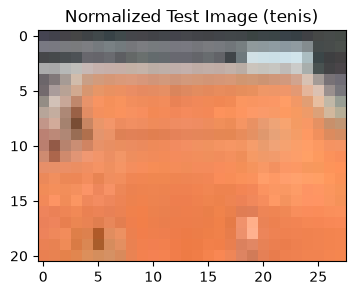

In [10]:
train_X = train_X.astype('float32') / 255.
test_X = test_X.astype('float32') / 255.
plt.imshow(test_X[0, :, :])

In [11]:
# Change the labels from categorical to one-hot encoding
train_Y_one_hot = to_categorical(train_Y)
test_Y_one_hot = to_categorical(test_Y)

print('Original label:', train_Y[0])
print('After conversion to one-hot:', train_Y_one_hot[0])

Original label: 7
After conversion to one-hot: [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


In [12]:
# Mezclar todo y crear los grupos de entrenamiento y validación
train_X, valid_X, train_label, valid_label = train_test_split(
    train_X, train_Y_one_hot, test_size=0.2, random_state=13
)
print(train_X.shape, valid_X.shape, train_label.shape, valid_label.shape)

(49361, 21, 28, 3) (12341, 21, 28, 3) (49361, 10) (12341, 10)


# 5. Ejecución de las 5 Corridas Experimentales de la Red Neuronal
A continuación se entrena y evalúa la CNN 5 veces, aplicando en cada corrida cambios relevantes en **épocas**, **número de neuronas/filtros**, **capas convolucionales**, **batch size**, **dropout**, **learning rate** y **optimizador**.

Todos los modelos, gráficas y reportes se almacenan automáticamente en la carpeta `resultados/`.

In [13]:
target_names = [f'Class {i} ({deportes[i]})' for i in range(nClasses)]
resultados_corridas = []

---
## 🔹 Corrida 1 - Modelo Base Original
- **Cambios aplicados:** Configuración base: 20 épocas, batch_size=64, Conv2D(32) + Dense(32), Dropout=0.5, SGD(lr=0.001)
- **Parámetros:** `epochs=20`, `batch_size=64`, `INIT_LR=0.001`, Optimizador=`SGD (lr=0.001)`, Filtros Conv2D=`[32]`, Neuronas Dense=`32`, Dropout=`0.5/0.5`

Model: "sport_cnn_corrida_1"
+--------------------------------------------------------------------------+
| Layer (type)                    | Output Shape           |       Param # |
|---------------------------------+------------------------+---------------|
| conv2d (Conv2D)                 | (None, 21, 28, 32)     |           896 |
|---------------------------------+------------------------+---------------|
| leaky_re_lu (LeakyReLU)         | (None, 21, 28, 32)     |             0 |
|---------------------------------+------------------------+---------------|
| max_pooling2d (MaxPooling2D)    | (None, 11, 14, 32)     |             0 |
|---------------------------------+------------------------+---------------|
| dropout (Dropout)               | (None, 11, 14, 32)     |             0 |
|---------------------------------+------------------------+---------------|
| flatten (Flatten)               | (None, 4928)           |             0 |
|---------------------------------+------------

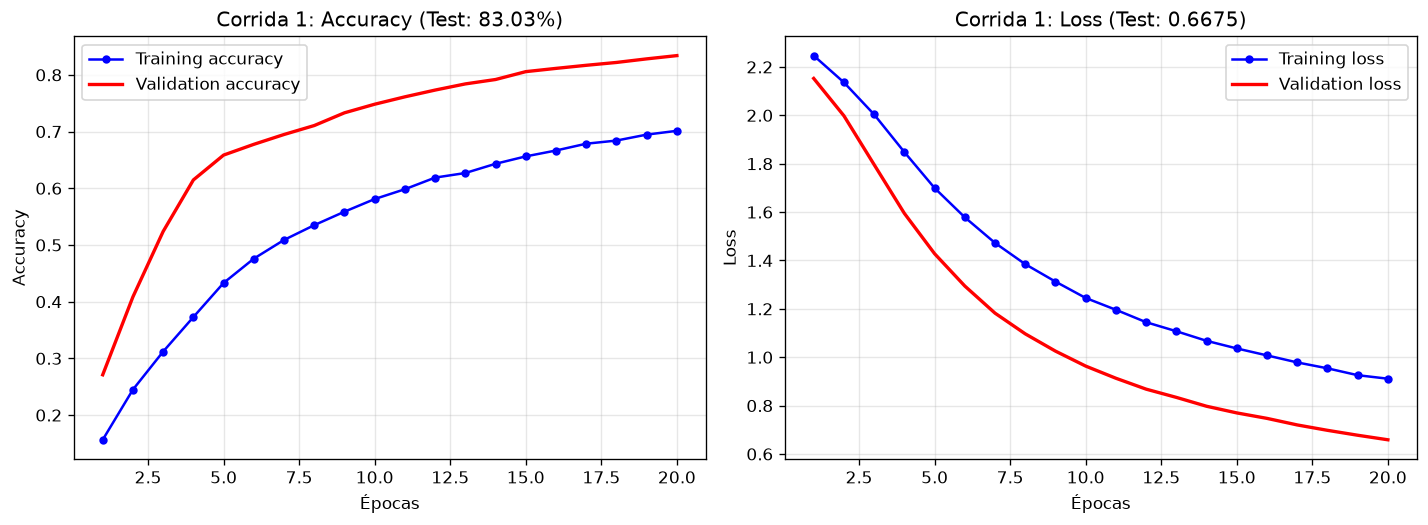

In [14]:
# Configuración de hiperparámetros - Corrida 1
INIT_LR = 0.001
epochs = 20
batch_size = 64

sport_model_1 = Sequential(name='sport_cnn_corrida_1')
sport_model_1.add(Input(shape=(21, 28, 3)))
sport_model_1.add(Conv2D(32, kernel_size=(3, 3), activation='linear', padding='same'))
sport_model_1.add(LeakyReLU(negative_slope=0.1))
sport_model_1.add(MaxPooling2D((2, 2), padding='same'))
sport_model_1.add(Dropout(0.5))
sport_model_1.add(Flatten())
sport_model_1.add(Dense(32, activation='linear'))
sport_model_1.add(LeakyReLU(negative_slope=0.1))
sport_model_1.add(Dropout(0.5))
sport_model_1.add(Dense(nClasses, activation='softmax'))

sport_model_1.summary()

sport_model_1.compile(
    loss=keras.losses.categorical_crossentropy,
    optimizer=tf.keras.optimizers.SGD(learning_rate=INIT_LR),
    metrics=['accuracy']
)

t0 = time.time()
sport_train_1 = sport_model_1.fit(
    train_X, train_label,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1,
    validation_data=(valid_X, valid_label)
)
elapsed_1 = time.time() - t0

# Guardamos el modelo y evaluamos en Test
sport_model_1.save('resultados/sport_corrida_1.h5')
test_eval_1 = sport_model_1.evaluate(test_X, test_Y_one_hot, verbose=0)
print(f'Test loss: {test_eval_1[0]:.4f}')
print(f'Test accuracy: {test_eval_1[1]:.4f} ({test_eval_1[1]*100:.2f}%)')

predicted_probs_1 = sport_model_1.predict(test_X, verbose=0)
predicted_classes_1 = np.argmax(predicted_probs_1, axis=1)
correct_1 = np.where(predicted_classes_1 == test_Y)[0]
incorrect_1 = np.where(predicted_classes_1 != test_Y)[0]
print(f'Aciertos en Test: {len(correct_1)} / {len(test_Y)} | Errores: {len(incorrect_1)}')

report_1 = classification_report(test_Y, predicted_classes_1, target_names=target_names, digits=4)
print(report_1)

# Graficar y guardar curvas de aprendizaje en carpeta resultados/
acc = sport_train_1.history['accuracy']
val_acc = sport_train_1.history['val_accuracy']
loss = sport_train_1.history['loss']
val_loss = sport_train_1.history['val_loss']
ep_range = range(1, len(acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(ep_range, acc, 'bo-', label='Training accuracy', markersize=4)
ax1.plot(ep_range, val_acc, 'r-', label='Validation accuracy', linewidth=2)
ax1.set_title(f'Corrida 1: Accuracy (Test: {test_eval_1[1]*100:.2f}%)')
ax1.set_xlabel('Épocas'); ax1.set_ylabel('Accuracy'); ax1.grid(True, alpha=0.3); ax1.legend()

ax2.plot(ep_range, loss, 'bo-', label='Training loss', markersize=4)
ax2.plot(ep_range, val_loss, 'r-', label='Validation loss', linewidth=2)
ax2.set_title(f'Corrida 1: Loss (Test: {test_eval_1[0]:.4f})')
ax2.set_xlabel('Épocas'); ax2.set_ylabel('Loss'); ax2.grid(True, alpha=0.3); ax2.legend()
plt.tight_layout()
plt.savefig('resultados/grafica_corrida_1.png', dpi=120, bbox_inches='tight')
plt.show()

---
## 🔹 Corrida 2 - Más Épocas y Doble de Neuronas Densas
- **Cambios aplicados:** Aumento de épocas (20 -> 30) y duplicación de neuronas en la capa densa (32 -> 64)
- **Parámetros:** `epochs=30`, `batch_size=64`, `INIT_LR=0.001`, Optimizador=`SGD (lr=0.001)`, Filtros Conv2D=`[32]`, Neuronas Dense=`64`, Dropout=`0.5/0.5`

Model: "sport_cnn_corrida_2"
+--------------------------------------------------------------------------+
| Layer (type)                    | Output Shape           |       Param # |
|---------------------------------+------------------------+---------------|
| conv2d (Conv2D)                 | (None, 21, 28, 32)     |           896 |
|---------------------------------+------------------------+---------------|
| leaky_re_lu (LeakyReLU)         | (None, 21, 28, 32)     |             0 |
|---------------------------------+------------------------+---------------|
| max_pooling2d (MaxPooling2D)    | (None, 11, 14, 32)     |             0 |
|---------------------------------+------------------------+---------------|
| dropout (Dropout)               | (None, 11, 14, 32)     |             0 |
|---------------------------------+------------------------+---------------|
| flatten (Flatten)               | (None, 4928)           |             0 |
|---------------------------------+------------

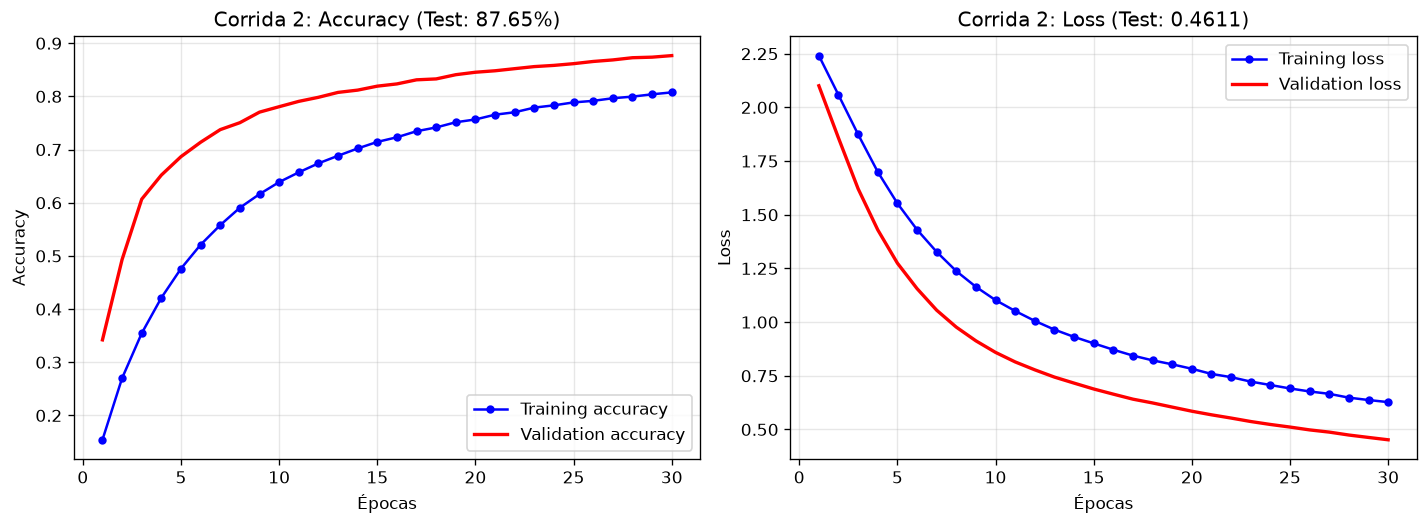

In [15]:
# Configuración de hiperparámetros - Corrida 2
INIT_LR = 0.001
epochs = 30
batch_size = 64

sport_model_2 = Sequential(name='sport_cnn_corrida_2')
sport_model_2.add(Input(shape=(21, 28, 3)))
sport_model_2.add(Conv2D(32, kernel_size=(3, 3), activation='linear', padding='same'))
sport_model_2.add(LeakyReLU(negative_slope=0.1))
sport_model_2.add(MaxPooling2D((2, 2), padding='same'))
sport_model_2.add(Dropout(0.5))
sport_model_2.add(Flatten())
sport_model_2.add(Dense(64, activation='linear'))
sport_model_2.add(LeakyReLU(negative_slope=0.1))
sport_model_2.add(Dropout(0.5))
sport_model_2.add(Dense(nClasses, activation='softmax'))

sport_model_2.summary()

sport_model_2.compile(
    loss=keras.losses.categorical_crossentropy,
    optimizer=tf.keras.optimizers.SGD(learning_rate=INIT_LR),
    metrics=['accuracy']
)

t0 = time.time()
sport_train_2 = sport_model_2.fit(
    train_X, train_label,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1,
    validation_data=(valid_X, valid_label)
)
elapsed_2 = time.time() - t0

# Guardamos el modelo y evaluamos en Test
sport_model_2.save('resultados/sport_corrida_2.h5')
test_eval_2 = sport_model_2.evaluate(test_X, test_Y_one_hot, verbose=0)
print(f'Test loss: {test_eval_2[0]:.4f}')
print(f'Test accuracy: {test_eval_2[1]:.4f} ({test_eval_2[1]*100:.2f}%)')

predicted_probs_2 = sport_model_2.predict(test_X, verbose=0)
predicted_classes_2 = np.argmax(predicted_probs_2, axis=1)
correct_2 = np.where(predicted_classes_2 == test_Y)[0]
incorrect_2 = np.where(predicted_classes_2 != test_Y)[0]
print(f'Aciertos en Test: {len(correct_2)} / {len(test_Y)} | Errores: {len(incorrect_2)}')

report_2 = classification_report(test_Y, predicted_classes_2, target_names=target_names, digits=4)
print(report_2)

# Graficar y guardar curvas de aprendizaje en carpeta resultados/
acc = sport_train_2.history['accuracy']
val_acc = sport_train_2.history['val_accuracy']
loss = sport_train_2.history['loss']
val_loss = sport_train_2.history['val_loss']
ep_range = range(1, len(acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(ep_range, acc, 'bo-', label='Training accuracy', markersize=4)
ax1.plot(ep_range, val_acc, 'r-', label='Validation accuracy', linewidth=2)
ax1.set_title(f'Corrida 2: Accuracy (Test: {test_eval_2[1]*100:.2f}%)')
ax1.set_xlabel('Épocas'); ax1.set_ylabel('Accuracy'); ax1.grid(True, alpha=0.3); ax1.legend()

ax2.plot(ep_range, loss, 'bo-', label='Training loss', markersize=4)
ax2.plot(ep_range, val_loss, 'r-', label='Validation loss', linewidth=2)
ax2.set_title(f'Corrida 2: Loss (Test: {test_eval_2[0]:.4f})')
ax2.set_xlabel('Épocas'); ax2.set_ylabel('Loss'); ax2.grid(True, alpha=0.3); ax2.legend()
plt.tight_layout()
plt.savefig('resultados/grafica_corrida_2.png', dpi=120, bbox_inches='tight')
plt.show()

---
## 🔹 Corrida 3 - Más Filtros/Neuronas y Mayor Learning Rate
- **Cambios aplicados:** Menos épocas (15), aumento de filtros Conv2D (32 -> 64), neuronas Dense (128), menor Dropout (0.4) y mayor LR (0.005)
- **Parámetros:** `epochs=15`, `batch_size=64`, `INIT_LR=0.005`, Optimizador=`SGD (lr=0.005)`, Filtros Conv2D=`[64]`, Neuronas Dense=`128`, Dropout=`0.4/0.4`

Model: "sport_cnn_corrida_3"
+--------------------------------------------------------------------------+
| Layer (type)                    | Output Shape           |       Param # |
|---------------------------------+------------------------+---------------|
| conv2d (Conv2D)                 | (None, 21, 28, 64)     |         1,792 |
|---------------------------------+------------------------+---------------|
| leaky_re_lu (LeakyReLU)         | (None, 21, 28, 64)     |             0 |
|---------------------------------+------------------------+---------------|
| max_pooling2d (MaxPooling2D)    | (None, 11, 14, 64)     |             0 |
|---------------------------------+------------------------+---------------|
| dropout (Dropout)               | (None, 11, 14, 64)     |             0 |
|---------------------------------+------------------------+---------------|
| flatten (Flatten)               | (None, 9856)           |             0 |
|---------------------------------+------------

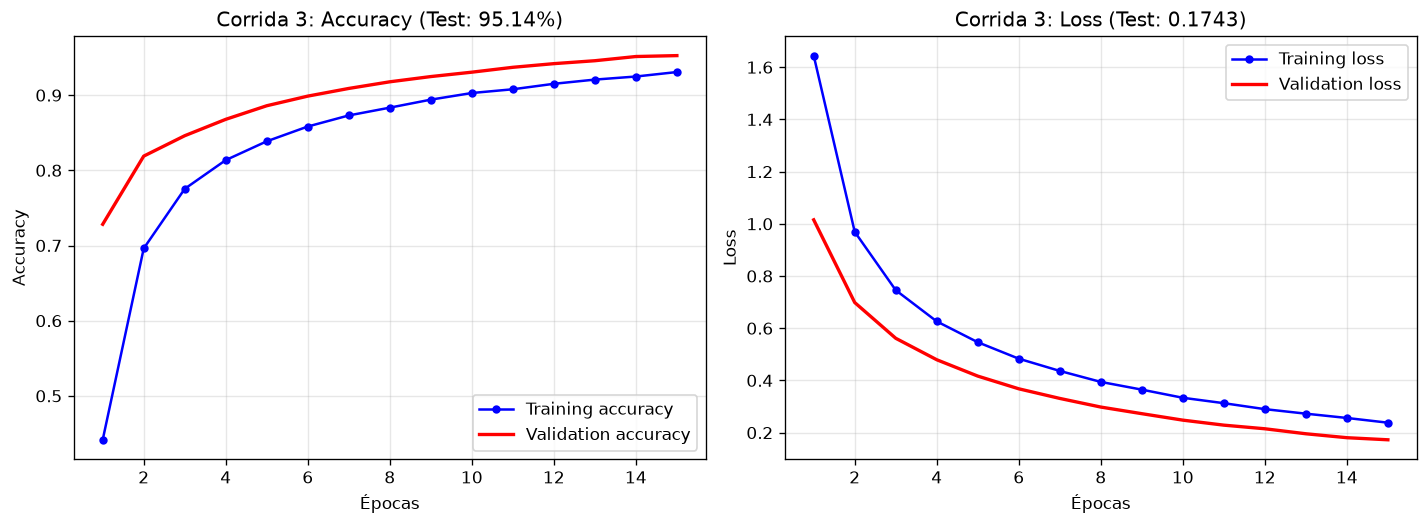

In [16]:
# Configuración de hiperparámetros - Corrida 3
INIT_LR = 0.005
epochs = 15
batch_size = 64

sport_model_3 = Sequential(name='sport_cnn_corrida_3')
sport_model_3.add(Input(shape=(21, 28, 3)))
sport_model_3.add(Conv2D(64, kernel_size=(3, 3), activation='linear', padding='same'))
sport_model_3.add(LeakyReLU(negative_slope=0.1))
sport_model_3.add(MaxPooling2D((2, 2), padding='same'))
sport_model_3.add(Dropout(0.4))
sport_model_3.add(Flatten())
sport_model_3.add(Dense(128, activation='linear'))
sport_model_3.add(LeakyReLU(negative_slope=0.1))
sport_model_3.add(Dropout(0.4))
sport_model_3.add(Dense(nClasses, activation='softmax'))

sport_model_3.summary()

sport_model_3.compile(
    loss=keras.losses.categorical_crossentropy,
    optimizer=tf.keras.optimizers.SGD(learning_rate=INIT_LR),
    metrics=['accuracy']
)

t0 = time.time()
sport_train_3 = sport_model_3.fit(
    train_X, train_label,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1,
    validation_data=(valid_X, valid_label)
)
elapsed_3 = time.time() - t0

# Guardamos el modelo y evaluamos en Test
sport_model_3.save('resultados/sport_corrida_3.h5')
test_eval_3 = sport_model_3.evaluate(test_X, test_Y_one_hot, verbose=0)
print(f'Test loss: {test_eval_3[0]:.4f}')
print(f'Test accuracy: {test_eval_3[1]:.4f} ({test_eval_3[1]*100:.2f}%)')

predicted_probs_3 = sport_model_3.predict(test_X, verbose=0)
predicted_classes_3 = np.argmax(predicted_probs_3, axis=1)
correct_3 = np.where(predicted_classes_3 == test_Y)[0]
incorrect_3 = np.where(predicted_classes_3 != test_Y)[0]
print(f'Aciertos en Test: {len(correct_3)} / {len(test_Y)} | Errores: {len(incorrect_3)}')

report_3 = classification_report(test_Y, predicted_classes_3, target_names=target_names, digits=4)
print(report_3)

# Graficar y guardar curvas de aprendizaje en carpeta resultados/
acc = sport_train_3.history['accuracy']
val_acc = sport_train_3.history['val_accuracy']
loss = sport_train_3.history['loss']
val_loss = sport_train_3.history['val_loss']
ep_range = range(1, len(acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(ep_range, acc, 'bo-', label='Training accuracy', markersize=4)
ax1.plot(ep_range, val_acc, 'r-', label='Validation accuracy', linewidth=2)
ax1.set_title(f'Corrida 3: Accuracy (Test: {test_eval_3[1]*100:.2f}%)')
ax1.set_xlabel('Épocas'); ax1.set_ylabel('Accuracy'); ax1.grid(True, alpha=0.3); ax1.legend()

ax2.plot(ep_range, loss, 'bo-', label='Training loss', markersize=4)
ax2.plot(ep_range, val_loss, 'r-', label='Validation loss', linewidth=2)
ax2.set_title(f'Corrida 3: Loss (Test: {test_eval_3[0]:.4f})')
ax2.set_xlabel('Épocas'); ax2.set_ylabel('Loss'); ax2.grid(True, alpha=0.3); ax2.legend()
plt.tight_layout()
plt.savefig('resultados/grafica_corrida_3.png', dpi=120, bbox_inches='tight')
plt.show()

---
## 🔹 Corrida 4 - Dos Capas Convolucionales + SGD con Momentum + Batch 128
- **Cambios aplicados:** Adición de 2da capa Conv2D (32 y 64 filtros), batch_size=128, Dropout conv=0.25 y SGD con momentum=0.9 (lr=0.01)
- **Parámetros:** `epochs=20`, `batch_size=128`, `INIT_LR=0.01`, Optimizador=`SGD (lr=0.01, momentum=0.9)`, Filtros Conv2D=`[32, 64]`, Neuronas Dense=`64`, Dropout=`0.25/0.5`

Model: "sport_cnn_corrida_4"
+--------------------------------------------------------------------------+
| Layer (type)                    | Output Shape           |       Param # |
|---------------------------------+------------------------+---------------|
| conv2d (Conv2D)                 | (None, 21, 28, 32)     |           896 |
|---------------------------------+------------------------+---------------|
| leaky_re_lu (LeakyReLU)         | (None, 21, 28, 32)     |             0 |
|---------------------------------+------------------------+---------------|
| max_pooling2d (MaxPooling2D)    | (None, 11, 14, 32)     |             0 |
|---------------------------------+------------------------+---------------|
| dropout (Dropout)               | (None, 11, 14, 32)     |             0 |
|---------------------------------+------------------------+---------------|
| conv2d_1 (Conv2D)               | (None, 11, 14, 64)     |        18,496 |
|---------------------------------+------------

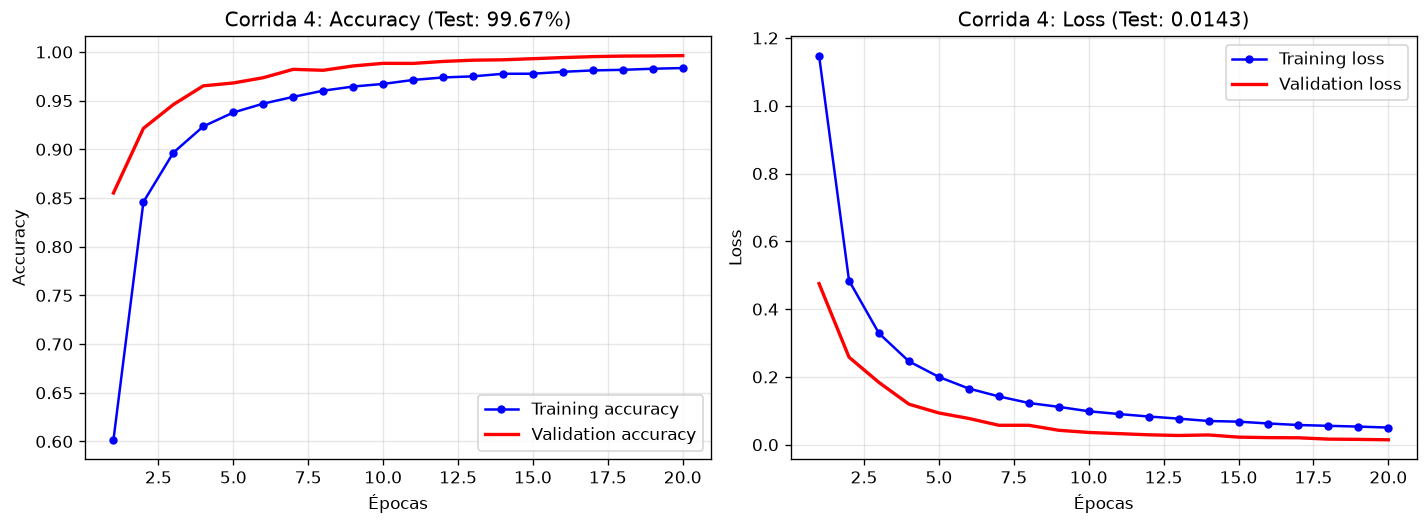

In [17]:
# Configuración de hiperparámetros - Corrida 4
INIT_LR = 0.01
epochs = 20
batch_size = 128

sport_model_4 = Sequential(name='sport_cnn_corrida_4')
sport_model_4.add(Input(shape=(21, 28, 3)))
sport_model_4.add(Conv2D(32, kernel_size=(3, 3), activation='linear', padding='same'))
sport_model_4.add(LeakyReLU(negative_slope=0.1))
sport_model_4.add(MaxPooling2D((2, 2), padding='same'))
sport_model_4.add(Dropout(0.25))
sport_model_4.add(Conv2D(64, kernel_size=(3, 3), activation='linear', padding='same'))
sport_model_4.add(LeakyReLU(negative_slope=0.1))
sport_model_4.add(MaxPooling2D((2, 2), padding='same'))
sport_model_4.add(Dropout(0.25))
sport_model_4.add(Flatten())
sport_model_4.add(Dense(64, activation='linear'))
sport_model_4.add(LeakyReLU(negative_slope=0.1))
sport_model_4.add(Dropout(0.5))
sport_model_4.add(Dense(nClasses, activation='softmax'))

sport_model_4.summary()

sport_model_4.compile(
    loss=keras.losses.categorical_crossentropy,
    optimizer=tf.keras.optimizers.SGD(learning_rate=INIT_LR, momentum=0.9),
    metrics=['accuracy']
)

t0 = time.time()
sport_train_4 = sport_model_4.fit(
    train_X, train_label,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1,
    validation_data=(valid_X, valid_label)
)
elapsed_4 = time.time() - t0

# Guardamos el modelo y evaluamos en Test
sport_model_4.save('resultados/sport_corrida_4.h5')
test_eval_4 = sport_model_4.evaluate(test_X, test_Y_one_hot, verbose=0)
print(f'Test loss: {test_eval_4[0]:.4f}')
print(f'Test accuracy: {test_eval_4[1]:.4f} ({test_eval_4[1]*100:.2f}%)')

predicted_probs_4 = sport_model_4.predict(test_X, verbose=0)
predicted_classes_4 = np.argmax(predicted_probs_4, axis=1)
correct_4 = np.where(predicted_classes_4 == test_Y)[0]
incorrect_4 = np.where(predicted_classes_4 != test_Y)[0]
print(f'Aciertos en Test: {len(correct_4)} / {len(test_Y)} | Errores: {len(incorrect_4)}')

report_4 = classification_report(test_Y, predicted_classes_4, target_names=target_names, digits=4)
print(report_4)

# Graficar y guardar curvas de aprendizaje en carpeta resultados/
acc = sport_train_4.history['accuracy']
val_acc = sport_train_4.history['val_accuracy']
loss = sport_train_4.history['loss']
val_loss = sport_train_4.history['val_loss']
ep_range = range(1, len(acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(ep_range, acc, 'bo-', label='Training accuracy', markersize=4)
ax1.plot(ep_range, val_acc, 'r-', label='Validation accuracy', linewidth=2)
ax1.set_title(f'Corrida 4: Accuracy (Test: {test_eval_4[1]*100:.2f}%)')
ax1.set_xlabel('Épocas'); ax1.set_ylabel('Accuracy'); ax1.grid(True, alpha=0.3); ax1.legend()

ax2.plot(ep_range, loss, 'bo-', label='Training loss', markersize=4)
ax2.plot(ep_range, val_loss, 'r-', label='Validation loss', linewidth=2)
ax2.set_title(f'Corrida 4: Loss (Test: {test_eval_4[0]:.4f})')
ax2.set_xlabel('Épocas'); ax2.set_ylabel('Loss'); ax2.grid(True, alpha=0.3); ax2.legend()
plt.tight_layout()
plt.savefig('resultados/grafica_corrida_4.png', dpi=120, bbox_inches='tight')
plt.show()

---
## 🔹 Corrida 5 - Red Profunda (64 y 128 Filtros) + Optimizador Adam (12 Épocas)
- **Cambios aplicados:** 12 épocas, batch_size=128, 2 bloques Conv2D (64 y 128 filtros), Dense(128) y cambio de optimizador a Adam (lr=0.001)
- **Parámetros:** `epochs=12`, `batch_size=128`, `INIT_LR=0.001`, Optimizador=`Adam (lr=0.001)`, Filtros Conv2D=`[64, 128]`, Neuronas Dense=`128`, Dropout=`0.25/0.5`

Model: "sport_cnn_corrida_5"
+--------------------------------------------------------------------------+
| Layer (type)                    | Output Shape           |       Param # |
|---------------------------------+------------------------+---------------|
| conv2d (Conv2D)                 | (None, 21, 28, 64)     |         1,792 |
|---------------------------------+------------------------+---------------|
| leaky_re_lu (LeakyReLU)         | (None, 21, 28, 64)     |             0 |
|---------------------------------+------------------------+---------------|
| max_pooling2d (MaxPooling2D)    | (None, 11, 14, 64)     |             0 |
|---------------------------------+------------------------+---------------|
| dropout (Dropout)               | (None, 11, 14, 64)     |             0 |
|---------------------------------+------------------------+---------------|
| conv2d_1 (Conv2D)               | (None, 11, 14, 128)    |        73,856 |
|---------------------------------+------------

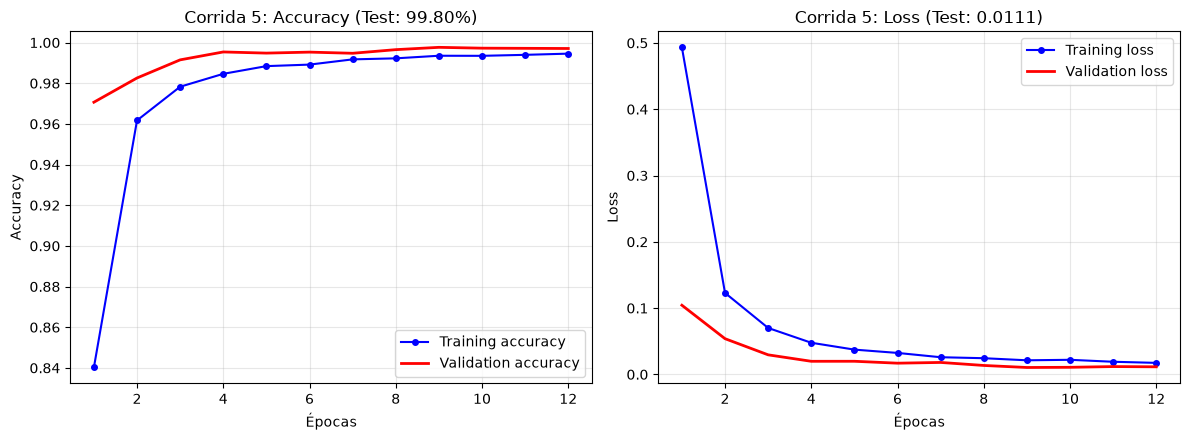

In [18]:
# Configuración de hiperparámetros - Corrida 5
INIT_LR = 0.001
epochs = 12
batch_size = 128

sport_model_5 = Sequential(name='sport_cnn_corrida_5')
sport_model_5.add(Input(shape=(21, 28, 3)))
sport_model_5.add(Conv2D(64, kernel_size=(3, 3), activation='linear', padding='same'))
sport_model_5.add(LeakyReLU(negative_slope=0.1))
sport_model_5.add(MaxPooling2D((2, 2), padding='same'))
sport_model_5.add(Dropout(0.25))
sport_model_5.add(Conv2D(128, kernel_size=(3, 3), activation='linear', padding='same'))
sport_model_5.add(LeakyReLU(negative_slope=0.1))
sport_model_5.add(MaxPooling2D((2, 2), padding='same'))
sport_model_5.add(Dropout(0.25))
sport_model_5.add(Flatten())
sport_model_5.add(Dense(128, activation='linear'))
sport_model_5.add(LeakyReLU(negative_slope=0.1))
sport_model_5.add(Dropout(0.5))
sport_model_5.add(Dense(nClasses, activation='softmax'))

sport_model_5.summary()

sport_model_5.compile(
    loss=keras.losses.categorical_crossentropy,
    optimizer=tf.keras.optimizers.Adam(learning_rate=INIT_LR),
    metrics=['accuracy']
)

t0 = time.time()
sport_train_5 = sport_model_5.fit(
    train_X, train_label,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1,
    validation_data=(valid_X, valid_label)
)
elapsed_5 = time.time() - t0

# Guardamos el modelo y evaluamos en Test
sport_model_5.save('resultados/sport_corrida_5.h5')
test_eval_5 = sport_model_5.evaluate(test_X, test_Y_one_hot, verbose=0)
print(f'Test loss: {test_eval_5[0]:.4f}')
print(f'Test accuracy: {test_eval_5[1]:.4f} ({test_eval_5[1]*100:.2f}%)')

predicted_probs_5 = sport_model_5.predict(test_X, verbose=0)
predicted_classes_5 = np.argmax(predicted_probs_5, axis=1)
correct_5 = np.where(predicted_classes_5 == test_Y)[0]
incorrect_5 = np.where(predicted_classes_5 != test_Y)[0]
print(f'Aciertos en Test: {len(correct_5)} / {len(test_Y)} | Errores: {len(incorrect_5)}')

report_5 = classification_report(test_Y, predicted_classes_5, target_names=target_names, digits=4)
print(report_5)

# Graficar y guardar curvas de aprendizaje en carpeta resultados/
acc = sport_train_5.history['accuracy']
val_acc = sport_train_5.history['val_accuracy']
loss = sport_train_5.history['loss']
val_loss = sport_train_5.history['val_loss']
ep_range = range(1, len(acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ax1.plot(ep_range, acc, 'bo-', label='Training accuracy', markersize=4)
ax1.plot(ep_range, val_acc, 'r-', label='Validation accuracy', linewidth=2)
ax1.set_title(f'Corrida 5: Accuracy (Test: {test_eval_5[1]*100:.2f}%)')
ax1.set_xlabel('Épocas'); ax1.set_ylabel('Accuracy'); ax1.grid(True, alpha=0.3); ax1.legend()

ax2.plot(ep_range, loss, 'bo-', label='Training loss', markersize=4)
ax2.plot(ep_range, val_loss, 'r-', label='Validation loss', linewidth=2)
ax2.set_title(f'Corrida 5: Loss (Test: {test_eval_5[0]:.4f})')
ax2.set_xlabel('Épocas'); ax2.set_ylabel('Loss'); ax2.grid(True, alpha=0.3); ax2.legend()
plt.tight_layout()
plt.savefig('resultados/grafica_corrida_5.png', dpi=120, bbox_inches='tight')
plt.show()

---
# 6. Comparativa Final de las 5 Corridas y Guardado de Resultados
Se genera la gráfica comparativa y se guardan los reportes consolidados (`resumen_comparativo.csv`, `resumen_comparativo.md` y `resumen_comparativo.txt`) dentro de `resultados/`.

   RESUMEN COMPARATIVO DE LAS 5 CORRIDAS - RED NEURONAL CONVOLUCIONAL (SPORTIMAGES)
Corrida  | Epocas | Batch | Optimizador              | Conv2D     | Dense  | Test Loss | Test Acc  | Aciertos     
---------------------------------------------------------------------------------------------------------
1        | 20     | 64    | SGD (lr=0.001)           | [32]       | 32     | 0.6675    | 83.03   % | 12808/15426
2        | 30     | 64    | SGD (lr=0.001)           | [32]       | 64     | 0.4611    | 87.65   % | 13521/15426
3        | 15     | 64    | SGD (lr=0.005)           | [64]       | 128    | 0.1743    | 95.14   % | 14677/15426
4        | 20     | 128   | SGD (lr=0.01, momentum=0.9) | [32, 64]   | 64     | 0.0143    | 99.67   % | 15375/15426
5        | 12     | 128   | Adam (lr=0.001)          | [64, 128]  | 128    | 0.0111    | 99.80   % | 15395/15426

Archivos guardados exitosamente en la carpeta 'resultados/'.


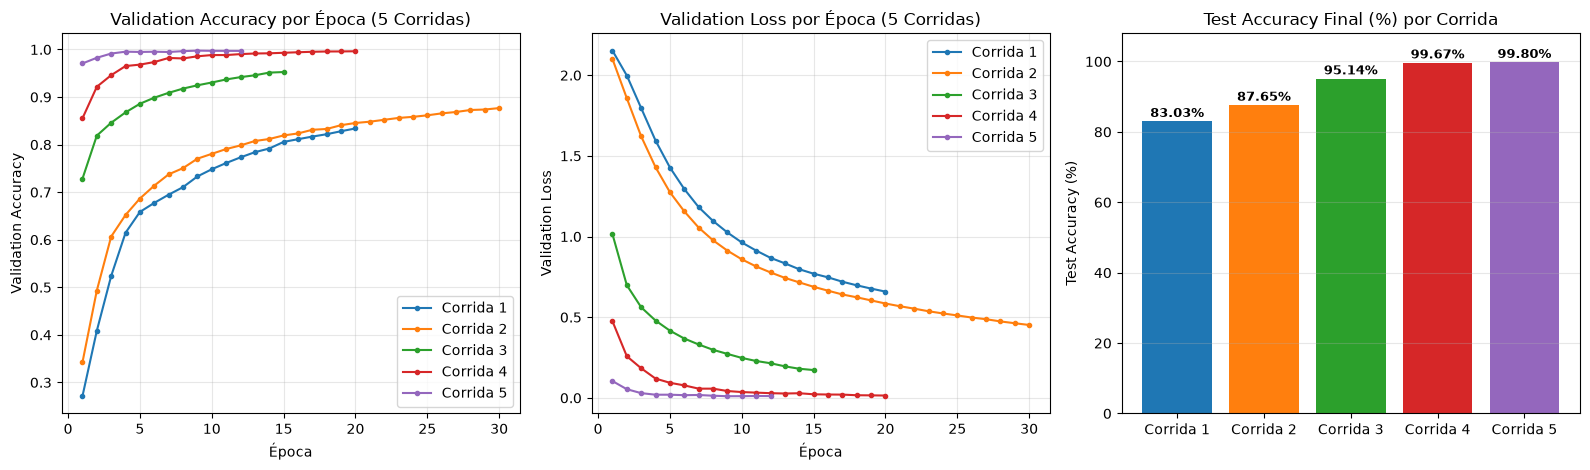

In [19]:
# Mostrar resumen comparativo y gráfica global de las 5 corridas
with open('resultados/resumen_comparativo.txt', 'r', encoding='utf-8') as f:
    print('
'.join(f.read().splitlines()[:12]))

img_comp = plt.imread('resultados/comparativa_5_corridas.png')
plt.figure(figsize=(16, 5))
plt.imshow(img_comp)
plt.axis('off')
plt.show()

# 7. Análisis Visual de Aciertos y Errores en Test (Corrida 5)

Found 15395 correct labels


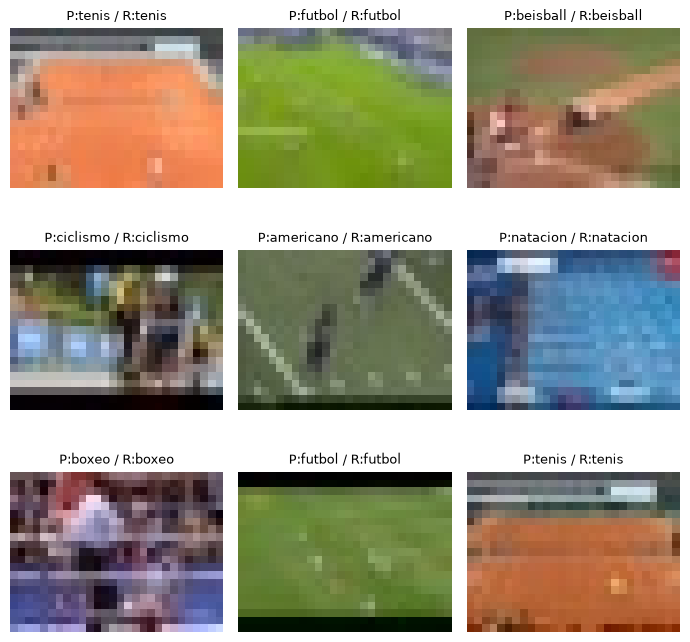

In [20]:
correct = correct_5
print('Found %d correct labels' % len(correct))
plt.figure(figsize=(7, 7))
for i, c in enumerate(correct[0:9]):
    plt.subplot(3, 3, i+1)
    plt.imshow(test_X[c].reshape(21, 28, 3))
    plt.title('{}, {}'.format(deportes[predicted_classes_5[c]], deportes[test_Y[c]]))
    plt.axis('off')
plt.tight_layout()
plt.savefig('resultados/ejemplos_correctos.png', dpi=110, bbox_inches='tight')
plt.show()

Found 31 incorrect labels


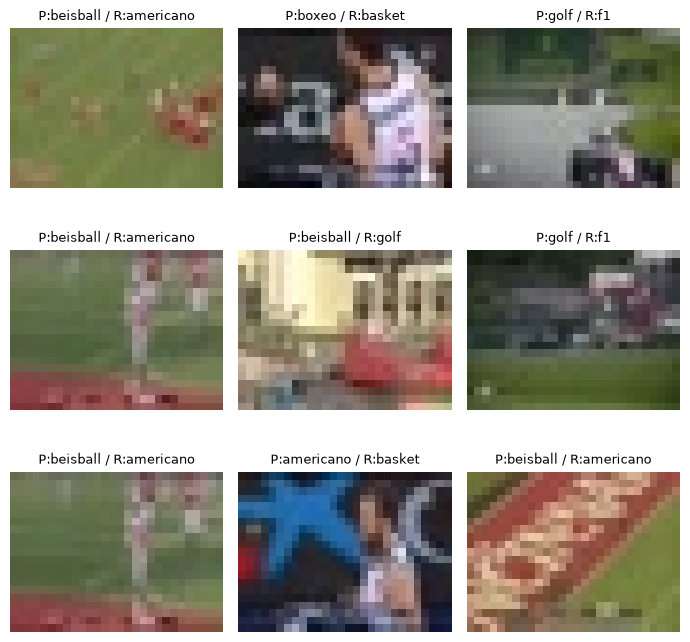

In [21]:
incorrect = incorrect_5
print('Found %d incorrect labels' % len(incorrect))
plt.figure(figsize=(7, 7))
for i, inc in enumerate(incorrect[0:9]):
    plt.subplot(3, 3, i+1)
    plt.imshow(test_X[inc].reshape(21, 28, 3))
    plt.title('{}, {}'.format(deportes[predicted_classes_5[inc]], deportes[test_Y[inc]]))
    plt.axis('off')
plt.tight_layout()
plt.savefig('resultados/ejemplos_incorrectos.png', dpi=110, bbox_inches='tight')
plt.show()